In [1]:
# =========================================================
# SEL 1 — Mount Drive, konfigurasi path, muat label + split
# =========================================================
from google.colab import drive
drive.mount('/content/drive')

import os, glob, shutil, json, gc, time
import numpy as np
import pandas as pd

# >>> UBAH BAGIAN INI jika nama folder di Drive berbeda <<<
ROOT        = "/content/drive/MyDrive/FOLDER TUGAS TPB KELOMPOK 6"
BASE_PATH   = f"{ROOT}/Dataset X-Ray"
LABEL_CSV   = f"{BASE_PATH}/boneage-training-dataset.csv"
SPLIT_CSV   = f"{BASE_PATH}/splits.csv"
DRIVE_CACHE = f"{ROOT}/cache"           # cache citra hasil preprocessing (sudah ada)
DRIVE_FEAT  = f"{ROOT}/features"        # BARU: salinan fitur CNN di Drive
DRIVE_OUT   = f"{ROOT}/hasil_paper"     # BARU: tabel, gambar, ringkasan untuk paper
PRED_DIR    = f"{DRIVE_OUT}/prediksi"   # BARU: prediksi tiap konfigurasi (agar bisa dilanjutkan)
FEAT_DIR    = "/content/features"       # fitur di disk lokal Colab (lebih cepat dibaca)
# >>> akhir bagian yang perlu diubah <<<

for d in [DRIVE_FEAT, DRIVE_OUT, PRED_DIR, FEAT_DIR]:
    os.makedirs(d, exist_ok=True)

SEED = 42
BACKBONES = ["resnet50", "densenet121", "efficientnet_b0"]
VARIANTS  = ["raw", "enh", "roi", "enh_roi"]

# Muat label dan split dengan urutan yang SAMA seperti saat cache citra dibuat
labels = pd.read_csv(LABEL_CSV)
splits = pd.read_csv(SPLIT_CSV)
labels["male"] = (labels["male"].astype(str).str.lower()
                  .map({"true": 1, "false": 0, "1": 1, "0": 0}).fillna(0).astype(int))
df = labels.merge(splits[["id", "split"]], on="id")
df["split"] = df["split"].astype(str).str.lower().replace({"validation": "val", "valid": "val"})
df = df.reset_index(drop=True)

tr = (df["split"] == "train").values
va = (df["split"] == "val").values
te = (df["split"] == "test").values
y = df["boneage"].values.astype(np.float32)
male = df["male"].values.astype(np.float32).reshape(-1, 1)

# Harus muncul: 12611 | 8827 | 1892 | 1892
print(f"Total {len(df)} | train {tr.sum()} | val {va.sum()} | test {te.sum()}")

Mounted at /content/drive
Total 12611 | train 8827 | val 1892 | test 1892


In [2]:
# =========================================================
# SEL 2 — Sinkronkan fitur CNN lokal <-> Drive, ekstrak ulang jika hilang
# =========================================================
PAIRS = [("resnet50", v) for v in VARIANTS] + [(b, "roi") for b in BACKBONES if b != "resnet50"]

def fname(b, v):
    return f"{b}_{v}.npy"

def sync_feature(b, v):
    """Salin file fitur antara disk lokal dan Drive. Return True jika fitur tersedia."""
    loc, drv = f"{FEAT_DIR}/{fname(b, v)}", f"{DRIVE_FEAT}/{fname(b, v)}"
    if os.path.exists(loc) and not os.path.exists(drv):
        shutil.copy(loc, drv)
    if os.path.exists(drv) and not os.path.exists(loc):
        shutil.copy(drv, loc)
    return os.path.exists(loc)

missing = [(b, v) for b, v in PAIRS if not sync_feature(b, v)]
print("Fitur yang perlu diekstrak ulang:", missing if missing else "tidak ada")

def load_variant(v):
    """Muat satu varian citra dari cache .npz (urutan chunk = urutan df)."""
    files = sorted(glob.glob(f"{DRIVE_CACHE}/chunk_*.npz"))
    return np.concatenate([np.load(f)[v] for f in files])

if missing:
    import torch, torch.nn as nn
    from torchvision import models as M
    from tqdm.auto import tqdm
    torch.manual_seed(SEED)
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    print("Device:", dev, "(jika 'cpu', ganti runtime ke GPU T4)")

    def get_backbone(name):
        if name == "resnet50":
            m = M.resnet50(weights=M.ResNet50_Weights.IMAGENET1K_V2); m.fc = nn.Identity()
        elif name == "densenet121":
            m = M.densenet121(weights=M.DenseNet121_Weights.IMAGENET1K_V1); m.classifier = nn.Identity()
        else:
            m = M.efficientnet_b0(weights=M.EfficientNet_B0_Weights.IMAGENET1K_V1); m.classifier = nn.Identity()
        return m.to(dev).eval()

    MEAN = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1)
    STD  = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)

    for v in sorted(set(v for _, v in missing)):
        Xv = load_variant(v)                       # muat satu varian sekali saja
        for b in [b for b, vv in missing if vv == v]:
            model, out = get_backbone(b), []
            with torch.no_grad():
                for i in tqdm(range(0, len(Xv), 128), desc=f"{b}/{v}"):
                    # grayscale -> 3 kanal, lalu normalisasi ImageNet
                    xb = torch.from_numpy(Xv[i:i + 128]).to(dev).float().div(255)
                    xb = (xb.unsqueeze(1).expand(-1, 3, -1, -1) - MEAN) / STD
                    with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(dev == "cuda")):
                        out.append(model(xb).float().cpu().numpy())
            np.save(f"{FEAT_DIR}/{fname(b, v)}", np.concatenate(out).astype(np.float32))
            shutil.copy(f"{FEAT_DIR}/{fname(b, v)}", DRIVE_FEAT)
            del model
            if dev == "cuda":
                torch.cuda.empty_cache()
        del Xv; gc.collect()

# Cek ukuran semua fitur
for b, v in PAIRS:
    F = np.load(f"{FEAT_DIR}/{fname(b, v)}", mmap_mode="r")
    assert F.shape[0] == len(df), f"Jumlah baris fitur {b}/{v} tidak cocok dengan df"
    print(f"{b:16s} {v:8s} {F.shape}")

Fitur yang perlu diekstrak ulang: [('resnet50', 'raw'), ('resnet50', 'roi'), ('resnet50', 'enh_roi'), ('densenet121', 'roi'), ('efficientnet_b0', 'roi')]
Device: cpu (jika 'cpu', ganti runtime ke GPU T4)
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 112MB/s]


resnet50/enh_roi:   0%|          | 0/99 [00:00<?, ?it/s]

resnet50/raw:   0%|          | 0/99 [00:00<?, ?it/s]

resnet50/roi:   0%|          | 0/99 [00:00<?, ?it/s]

...

densenet121/roi:   0%|          | 0/99 [00:00<?, ?it/s]

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 97.9MB/s]


efficientnet_b0/roi:   0%|          | 0/99 [00:00<?, ?it/s]

resnet50         raw      (12611, 2048)
resnet50         enh      (12611, 2048)
resnet50         roi      (12611, 2048)
resnet50         enh_roi  (12611, 2048)
densenet121      roi      (12611, 1024)
efficientnet_b0  roi      (12611, 1280)


In [3]:
# =========================================================
# SEL 3 — Fungsi bantu: metrik, fitur, model, cache prediksi, tuning
# =========================================================
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import pearsonr
from xgboost import XGBRegressor
import torch

GPU = torch.cuda.is_available()
MU, SD = y[tr].mean(), y[tr].std()          # target distandardisasi memakai statistik train
ys_tr, ys_va = (y[tr] - MU) / SD, (y[va] - MU) / SD

# Baseline: selalu menebak rata-rata usia train
BASE_VAL  = mean_absolute_error(y[va], np.full(va.sum(), MU))
BASE_TEST = mean_absolute_error(y[te], np.full(te.sum(), MU))
print(f"Baseline MAE val {BASE_VAL:.2f} | test {BASE_TEST:.2f}")

def metrics(yt, yp):
    return {"MAE": mean_absolute_error(yt, yp), "RMSE": mean_squared_error(yt, yp) ** 0.5,
            "R2": r2_score(yt, yp), "Pearson": pearsonr(yt, yp)[0]}

_feat_mem = {}
def get_X(backbone, variant, pca=None, use_sex=True):
    """Fitur siap pakai: standardisasi (fit di train) -> opsional PCA -> opsional + jenis kelamin."""
    k = (backbone, variant, pca, use_sex)
    if k not in _feat_mem:
        F = np.load(f"{FEAT_DIR}/{fname(backbone, variant)}")
        Z = StandardScaler().fit(F[tr]).transform(F)
        if pca:
            Z = PCA(pca, random_state=SEED).fit(Z[tr]).transform(Z)
        if use_sex:
            Z = np.hstack([Z, male])
        _feat_mem[k] = Z.astype(np.float32)
    return _feat_mem[k]

def clear_mem():
    _feat_mem.clear(); gc.collect()

def make_and_fit(reg, p, Xf):
    """Buat dan latih satu regressor dengan parameter p."""
    if reg == "ridge":
        return Ridge(alpha=p["alpha"]).fit(Xf[tr], ys_tr)
    if reg == "svr":
        return SVR(kernel="rbf", C=p["C"], epsilon=p["eps"], cache_size=2000).fit(Xf[tr], ys_tr)
    if reg == "mlp":
        # early stopping memakai 10% data TRAIN (bukan val) sebagai validasi internal
        return MLPRegressor(hidden_layer_sizes=tuple(p["hidden"]), alpha=p["alpha"], batch_size=256,
                            learning_rate_init=1e-3, max_iter=300, early_stopping=True,
                            validation_fraction=0.1, n_iter_no_change=15,
                            random_state=SEED).fit(Xf[tr], ys_tr)
    if reg == "xgb":
        # jumlah pohon ditentukan oleh early stopping pada data val
        m = XGBRegressor(n_estimators=2000, learning_rate=0.05, max_depth=p["depth"], subsample=0.8,
                         colsample_bytree=0.5, tree_method="hist", device="cuda" if GPU else "cpu",
                         early_stopping_rounds=50, random_state=SEED, n_jobs=2)
        m.fit(Xf[tr], ys_tr, eval_set=[(Xf[va], ys_va)], verbose=False)
        return m

def pkey(p):
    s = "-".join(f"{k}{v}" for k, v in sorted(p.items()))
    return s.replace(" ", "").replace(",", "x").replace("(", "").replace(")", "")

def run_config(backbone, variant, reg, p, pca=None, use_sex=True):
    """Latih satu konfigurasi. Prediksi disimpan ke Drive sehingga tidak dihitung ulang."""
    tag = f"{backbone}__{variant}__{reg}__{pkey(p)}__pca{pca}__sex{int(use_sex)}"
    f = f"{PRED_DIR}/{tag}.npz"
    if os.path.exists(f):
        d = np.load(f)
        return d["pv"], d["pt"], json.loads(str(d["info"]))
    t0 = time.time()
    Xf = get_X(backbone, variant, pca, use_sex)
    m = make_and_fit(reg, p, Xf)
    pv, pt = m.predict(Xf[va]) * SD + MU, m.predict(Xf[te]) * SD + MU
    info = {"fit_sec": round(time.time() - t0, 1)}
    if reg == "xgb": info["best_iter"] = int(m.best_iteration)
    if reg == "mlp": info["n_iter"] = int(m.n_iter_)
    np.savez(f, pv=pv, pt=pt, info=json.dumps(info))
    return pv, pt, info

def tune(backbone, variant, reg, grid, pca=None, use_sex=True):
    """Coba semua parameter di grid, pilih berdasarkan MAE VALIDASI."""
    log = []
    for p in grid:
        pv, pt, info = run_config(backbone, variant, reg, p, pca, use_sex)
        mv = mean_absolute_error(y[va], pv)
        log.append((mv, p, pv, pt, info))
        print(f"  {backbone:15s} {reg:5s} {str(p):38s} val MAE {mv:6.2f}  ({info['fit_sec']} s)")
    mv, p, pv, pt, info = min(log, key=lambda r: r[0])
    return {"backbone": backbone, "variant": variant, "regressor": reg, "pca": pca,
            "use_sex": use_sex, "params": p, "info": info, "pv": pv, "pt": pt}

def to_row(r):
    mv, mt = metrics(y[va], r["pv"]), metrics(y[te], r["pt"])
    return {"backbone": r["backbone"], "variant": r["variant"], "regressor": r["regressor"],
            "pca": r["pca"], "use_sex": r["use_sex"], "params": str(r["params"]),
            **{f"val_{k}": v for k, v in mv.items()}, **{f"test_{k}": v for k, v in mt.items()}}

# Grid hyperparameter
GRID = {
    "ridge": [{"alpha": a} for a in [1, 10, 100, 1000, 3000, 10000]],
    "mlp":   [{"hidden": h, "alpha": a} for h in [(256,), (512, 256)] for a in [1e-4, 1e-3, 1e-2]],
    "xgb":   [{"depth": d} for d in [3, 5]],
}
SVR_C, SVR_EPS = [1, 3, 10, 30], [0.05, 0.2]

def tune_svr(backbone, variant, use_sex=True):
    """SVR dua tahap: (1) cari C terbaik dengan eps=0.1, (2) cari eps terbaik pada C itu."""
    s1 = tune(backbone, variant, "svr", [{"C": c, "eps": 0.1} for c in SVR_C], use_sex=use_sex)
    s2 = tune(backbone, variant, "svr", [{"C": s1["params"]["C"], "eps": e} for e in SVR_EPS], use_sex=use_sex)
    return s1 if mean_absolute_error(y[va], s1["pv"]) <= mean_absolute_error(y[va], s2["pv"]) else s2

COLS = ["backbone", "variant", "regressor", "params", "val_MAE", "test_MAE", "test_RMSE", "test_R2", "test_Pearson"]

Baseline MAE val 33.78 | test 33.60


In [4]:
# =========================================================
# SEL 4 — Ablation preprocessing (ResNet50), konfigurasi regressor tetap
# Perkiraan waktu: ±20 menit (SVR 4 kali)
# =========================================================
abl_res = []
for v in VARIANTS:
    print(f"\n=== resnet50 / {v} ===")
    abl_res.append(tune("resnet50", v, "ridge", GRID["ridge"]))
    pv, pt, info = run_config("resnet50", v, "svr", {"C": 10, "eps": 0.1})
    print(f"  resnet50        svr   {{'C': 10, 'eps': 0.1}} (tetap)            val MAE {mean_absolute_error(y[va], pv):6.2f}")
    abl_res.append({"backbone": "resnet50", "variant": v, "regressor": "svr", "pca": None, "use_sex": True,
                    "params": {"C": 10, "eps": 0.1}, "info": info, "pv": pv, "pt": pt})
clear_mem()

tab1 = pd.DataFrame([to_row(r) for r in abl_res])
tab1.to_csv(f"{DRIVE_OUT}/tabel1_ablation.csv", index=False)
display(tab1[COLS].round(2))

# Varian terbaik dipilih dari val MAE (Ridge, karena alpha-nya sudah di-tuning)
VAR = tab1[tab1.regressor == "ridge"].sort_values("val_MAE").iloc[0]["variant"]
print("Varian terbaik (val MAE, Ridge):", VAR)


=== resnet50 / raw ===
  resnet50        ridge {'alpha': 1}                           val MAE  14.67  (5.7 s)
  resnet50        ridge {'alpha': 10}                          val MAE  14.64  (2.1 s)
  resnet50        ridge {'alpha': 100}                         val MAE  14.43  (2.4 s)
  resnet50        ridge {'alpha': 1000}                        val MAE  14.28  (1.9 s)
  resnet50        ridge {'alpha': 3000}                        val MAE  14.86  (1.9 s)
  resnet50        ridge {'alpha': 10000}                       val MAE  16.06  (3.0 s)
  resnet50        svr   {'C': 10, 'eps': 0.1} (tetap)            val MAE  15.40

=== resnet50 / enh ===
  resnet50        ridge {'alpha': 1}                           val MAE  14.48  (2.3 s)
  resnet50        ridge {'alpha': 10}                          val MAE  14.45  (1.7 s)
  resnet50        ridge {'alpha': 100}                         val MAE  14.26  (2.3 s)
  resnet50        ridge {'alpha': 1000}                        val MAE  14.13  (1.6 s)
  

,backbone,variant,regressor,params,val_MAE,test_MAE,test_RMSE,test_R2,test_Pearson
0,resnet50,raw,ridge,{'alpha': 1000},14.28,14.11,18.13,0.80,0.90
1,resnet50,raw,svr,"{'C': 10, 'eps': 0.1}",15.40,15.02,19.71,0.77,0.88
2,resnet50,enh,ridge,{'alpha': 1000},14.13,14.47,18.41,0.80,0.89
3,resnet50,enh,svr,"{'C': 10, 'eps': 0.1}",15.09,14.91,19.32,0.78,0.88
4,resnet50,roi,ridge,{'alpha': 100},13.59,13.78,17.99,0.81,0.90
5,resnet50,roi,svr,"{'C': 10, 'eps': 0.1}",15.01,14.61,19.36,0.78,0.88
6,resnet50,enh_roi,ridge,{'alpha': 1000},13.75,13.85,17.91,0.81,0.90
7,resnet50,enh_roi,svr,"{'C': 10, 'eps': 0.1}",15.10,14.46,18.87,0.79,0.89


Varian terbaik (val MAE, Ridge): roi


In [5]:
# =========================================================
# SEL 5 — Tuning 3 backbone x 4 regressor pada varian terbaik
# Perkiraan waktu: 1,5–2 jam. Aman jika terputus (hasil tersimpan per konfigurasi).
# =========================================================
best_per = {}
for b in BACKBONES:
    print(f"\n=== {b} / {VAR} ===")
    best_per[(b, "ridge")] = tune(b, VAR, "ridge", GRID["ridge"])
    best_per[(b, "svr")]   = tune_svr(b, VAR)
    best_per[(b, "mlp")]   = tune(b, VAR, "mlp", GRID["mlp"])
    best_per[(b, "xgb")]   = tune(b, VAR, "xgb", GRID["xgb"], pca=128)
    clear_mem()

tab2 = pd.DataFrame([to_row(r) for r in best_per.values()])
tab2.to_csv(f"{DRIVE_OUT}/tabel2_backbone_regressor.csv", index=False)
display(tab2[COLS].round(2))


=== resnet50 / roi ===
  resnet50        ridge {'alpha': 1}                           val MAE  13.84  (2.4 s)
  resnet50        ridge {'alpha': 10}                          val MAE  13.80  (1.5 s)
  resnet50        ridge {'alpha': 100}                         val MAE  13.59  (1.1 s)
  resnet50        ridge {'alpha': 1000}                        val MAE  13.66  (1.0 s)
  resnet50        ridge {'alpha': 3000}                        val MAE  14.52  (1.0 s)
  resnet50        ridge {'alpha': 10000}                       val MAE  16.02  (1.0 s)
  resnet50        svr   {'C': 1, 'eps': 0.1}                   val MAE  15.38  (216.2 s)
  resnet50        svr   {'C': 3, 'eps': 0.1}                   val MAE  14.96  (209.6 s)
  resnet50        svr   {'C': 10, 'eps': 0.1}                  val MAE  15.01  (210.9 s)
  resnet50        svr   {'C': 30, 'eps': 0.1}                  val MAE  15.01  (208.5 s)
  resnet50        svr   {'C': 3, 'eps': 0.05}                  val MAE  14.83  (237.9 s)
  resnet5

,backbone,variant,regressor,params,val_MAE,test_MAE,test_RMSE,test_R2,test_Pearson
0,resnet50,roi,ridge,{'alpha': 100},13.59,13.78,17.99,0.81,0.90
1,resnet50,roi,svr,"{'C': 3, 'eps': 0.05}",14.83,14.41,19.15,0.78,0.89
2,resnet50,roi,mlp,"{'hidden': (512, 256), 'alpha': 0.01}",13.47,12.96,16.86,0.83,0.91
3,resnet50,roi,xgb,{'depth': 5},15.18,14.64,19.22,0.78,0.88
4,densenet121,roi,ridge,{'alpha': 100},12.00,12.32,15.99,0.85,0.92
5,densenet121,roi,svr,"{'C': 10, 'eps': 0.05}",12.12,11.76,15.44,0.86,0.93
6,densenet121,roi,mlp,"{'hidden': (256,), 'alpha': 0.001}",12.33,12.42,16.01,0.85,0.92
7,densenet121,roi,xgb,{'depth': 5},13.06,13.01,17.07,0.83,0.91
8,efficientnet_b0,roi,ridge,{'alpha': 100},13.17,12.85,17.10,0.83,0.91
9,efficientnet_b0,roi,svr,"{'C': 3, 'eps': 0.05}",13.56,12.69,17.23,0.82,0.91


In [6]:
# =========================================================
# SEL 6 — Ensemble: anggota & bobot dipilih dari val, test hanya dilaporkan
# =========================================================
members = {}
for b in BACKBONES:
    cands = [best_per[(b, r)] for r in ["ridge", "svr", "mlp", "xgb"]]
    members[b] = min(cands, key=lambda r: mean_absolute_error(y[va], r["pv"]))
    print(f"{b:16s} -> {members[b]['regressor']} {members[b]['params']}")

PV = np.stack([members[b]["pv"] for b in BACKBONES], axis=1)
PT = np.stack([members[b]["pt"] for b in BACKBONES], axis=1)

# Grid bobot dengan langkah 0,05 (jumlah bobot = 1)
best_w, best_mv = None, np.inf
for i in range(21):
    for j in range(21 - i):
        w = np.array([i, j, 20 - i - j]) / 20
        mv = mean_absolute_error(y[va], PV @ w)
        if mv < best_mv:
            best_w, best_mv = w, mv

w_eq = np.ones(3) / 3
ens_eq = {"backbone": "ensemble", "variant": VAR, "regressor": "rata-rata sama", "pca": None, "use_sex": True,
          "params": dict(zip(BACKBONES, w_eq.round(2))), "pv": PV @ w_eq, "pt": PT @ w_eq}
ens_w  = {"backbone": "ensemble", "variant": VAR, "regressor": "bobot (val)", "pca": None, "use_sex": True,
          "params": dict(zip(BACKBONES, best_w.round(2))), "pv": PV @ best_w, "pt": PT @ best_w}

# Model tunggal terbaik (val MAE) dari seluruh Tabel 2
single_best = min(best_per.values(), key=lambda r: mean_absolute_error(y[va], r["pv"]))

tab3 = pd.DataFrame([to_row(r) for r in [single_best, ens_eq, ens_w]])
tab3.to_csv(f"{DRIVE_OUT}/tabel3_ensemble.csv", index=False)
display(tab3[COLS].round(2))

# Model FINAL = yang val MAE-nya paling rendah di antara ketiganya
FINAL = min([single_best, ens_eq, ens_w], key=lambda r: mean_absolute_error(y[va], r["pv"]))
FINAL_NAME = f"{FINAL['backbone']} + {FINAL['regressor']}"
print("Model final (dipilih dari val):", FINAL_NAME, FINAL["params"])

resnet50         -> mlp {'hidden': (512, 256), 'alpha': 0.01}
densenet121      -> ridge {'alpha': 100}
efficientnet_b0  -> mlp {'hidden': (512, 256), 'alpha': 0.01}


,backbone,variant,regressor,params,val_MAE,test_MAE,test_RMSE,test_R2,test_Pearson
0,densenet121,roi,ridge,{'alpha': 100},12.00,12.32,15.99,0.85,0.92
1,ensemble,roi,rata-rata sama,"{'resnet50': np.float64(0.33), 'densenet121': ...",10.66,10.39,13.70,0.89,0.94
2,ensemble,roi,bobot (val),"{'resnet50': np.float64(0.2), 'densenet121': n...",10.55,10.45,13.76,0.89,0.94


Model final (dipilih dari val): ensemble + bobot (val) {'resnet50': np.float64(0.2), 'densenet121': np.float64(0.5), 'efficientnet_b0': np.float64(0.3)}


In [7]:
# =========================================================
# SEL 7 — Dengan vs tanpa fitur jenis kelamin (konfigurasi tunggal terbaik)
# =========================================================
sb = single_best
pv_nosex, pt_nosex, _ = run_config(sb["backbone"], sb["variant"], sb["regressor"], sb["params"],
                                   sb["pca"], use_sex=False)
no_sex = {**sb, "use_sex": False, "pv": pv_nosex, "pt": pt_nosex}

tab_sex = pd.DataFrame([to_row(sb), to_row(no_sex)])
tab_sex.to_csv(f"{DRIVE_OUT}/tabel_fitur_gender.csv", index=False)
display(tab_sex[["backbone", "regressor", "use_sex", "val_MAE", "test_MAE", "test_RMSE", "test_R2"]].round(2))
clear_mem()

,backbone,regressor,use_sex,val_MAE,test_MAE,test_RMSE,test_R2
0,densenet121,ridge,True,12.0,12.32,15.99,0.85
1,densenet121,ridge,False,14.3,14.58,18.58,0.79


In [8]:
# =========================================================
# SEL 8 — MAE dan bias per kelompok usia & per jenis kelamin (test set)
# =========================================================
yt, pt_f, pt_s = y[te], FINAL["pt"], single_best["pt"]
sex_te = df["male"].values[te]
bins, names = [0, 60, 120, 180, 229], ["0–5 th", "5–10 th", "10–15 th", "15–19 th"]
grp = pd.cut(yt, bins=bins, labels=names, right=False)

def summarize(mask):
    return {"n": int(mask.sum()),
            "MAE_final": mean_absolute_error(yt[mask], pt_f[mask]),
            "Bias_final": float((pt_f[mask] - yt[mask]).mean()),
            "MAE_single_best": mean_absolute_error(yt[mask], pt_s[mask]),
            "MAE_baseline": mean_absolute_error(yt[mask], np.full(mask.sum(), MU))}

tab_age = pd.DataFrame([{"kelompok": g, **summarize(np.asarray(grp == g))} for g in names])
tab_sexgrp = pd.DataFrame([{"jenis_kelamin": s, **summarize(sex_te == k)} for s, k in [("Laki-laki", 1), ("Perempuan", 0)]])
tab_age.to_csv(f"{DRIVE_OUT}/tabel_per_usia.csv", index=False)
tab_sexgrp.to_csv(f"{DRIVE_OUT}/tabel_per_gender.csv", index=False)
print("Model final:", FINAL_NAME)
display(tab_age.round(2)); display(tab_sexgrp.round(2))

Model final: ensemble + bobot (val)


,kelompok,n,MAE_final,Bias_final,MAE_single_best,MAE_baseline
0,0–5 th,117,14.16,9.63,17.45,88.17
1,5–10 th,534,11.91,7.46,13.64,38.38
2,10–15 th,1087,9.10,-2.14,10.83,21.23
3,15–19 th,154,12.14,-10.19,14.28,62.92


,jenis_kelamin,n,MAE_final,Bias_final,MAE_single_best,MAE_baseline
0,Laki-laki,1027,10.11,-1.48,12.23,35.94
1,Perempuan,865,10.86,3.17,12.41,30.82


In [9]:
# =========================================================
# SEL 9 — Bootstrap 95% CI untuk MAE dan selisih MAE (test set, 2000 resample)
# =========================================================
B, n_te = 2000, int(te.sum())
rng = np.random.default_rng(SEED)
IDX = rng.integers(0, n_te, size=(B, n_te))     # indeks resample yang SAMA untuk semua model (paired)

def ci_mae(pt):
    e = np.abs(y[te] - pt); bs = e[IDX].mean(1)
    return e.mean(), *np.percentile(bs, [2.5, 97.5])

def ci_diff(p_a, p_b):
    """Selisih MAE(A) - MAE(B). Positif = B lebih baik."""
    d = np.abs(y[te] - p_a) - np.abs(y[te] - p_b); bs = d[IDX].mean(1)
    lo, hi = np.percentile(bs, [2.5, 97.5])
    return d.mean(), lo, hi, not (lo <= 0 <= hi)

get_abl = lambda v, reg: next(r for r in abl_res if r["variant"] == v and r["regressor"] == reg)

# CI MAE untuk model-model utama
rows = []
for name, r in [(f"ResNet50-{reg}-{v}", get_abl(v, reg)) for reg in ["ridge", "svr"] for v in VARIANTS] + \
               [(f"single best ({single_best['backbone']}-{single_best['regressor']})", single_best),
                ("ensemble rata-rata", ens_eq), ("ensemble berbobot", ens_w)]:
    m, lo, hi = ci_mae(r["pt"])
    rows.append({"model": name, "MAE": m, "CI_low": lo, "CI_high": hi})
tab_ci = pd.DataFrame(rows)

# Perbandingan berpasangan
comps = [(f"ResNet50-{reg}: raw vs {v}", get_abl("raw", reg)["pt"], get_abl(v, reg)["pt"])
         for reg in ["ridge", "svr"] for v in ["enh", "roi", "enh_roi"]]
comps += [("single best vs ensemble berbobot", single_best["pt"], ens_w["pt"]),
          ("tanpa vs dengan fitur jenis kelamin", pt_nosex, single_best["pt"])]
tab_diff = pd.DataFrame([{"perbandingan (A vs B)": n, **dict(zip(["selisih_MAE", "CI_low", "CI_high", "bermakna"], ci_diff(a, b)))}
                         for n, a, b in comps])

tab_ci.to_csv(f"{DRIVE_OUT}/bootstrap_ci_mae.csv", index=False)
tab_diff.to_csv(f"{DRIVE_OUT}/bootstrap_selisih.csv", index=False)
display(tab_ci.round(2)); display(tab_diff.round(2))

,model,MAE,CI_low,CI_high
0,ResNet50-ridge-raw,14.11,13.60,14.62
1,ResNet50-ridge-enh,14.47,13.99,14.97
2,ResNet50-ridge-roi,13.78,13.25,14.32
3,ResNet50-ridge-enh_roi,13.85,13.34,14.38
4,ResNet50-svr-raw,15.02,14.43,15.62
5,ResNet50-svr-enh,14.91,14.36,15.45
6,ResNet50-svr-roi,14.61,14.03,15.19
7,ResNet50-svr-enh_roi,14.46,13.92,15.05
8,single best (densenet121-ridge),12.32,11.87,12.78
9,ensemble rata-rata,10.39,10.00,10.80


,perbandingan (A vs B),selisih_MAE,CI_low,CI_high,bermakna
0,ResNet50-ridge: raw vs enh,-0.36,-0.84,0.12,False
1,ResNet50-ridge: raw vs roi,0.33,-0.29,0.93,False
2,ResNet50-ridge: raw vs enh_roi,0.26,-0.32,0.83,False
3,ResNet50-svr: raw vs enh,0.11,-0.31,0.52,False
4,ResNet50-svr: raw vs roi,0.41,-0.12,0.97,False
5,ResNet50-svr: raw vs enh_roi,0.56,-0.01,1.11,False
6,single best vs ensemble berbobot,1.86,1.60,2.13,True
7,tanpa vs dengan fitur jenis kelamin,2.27,1.92,2.58,True


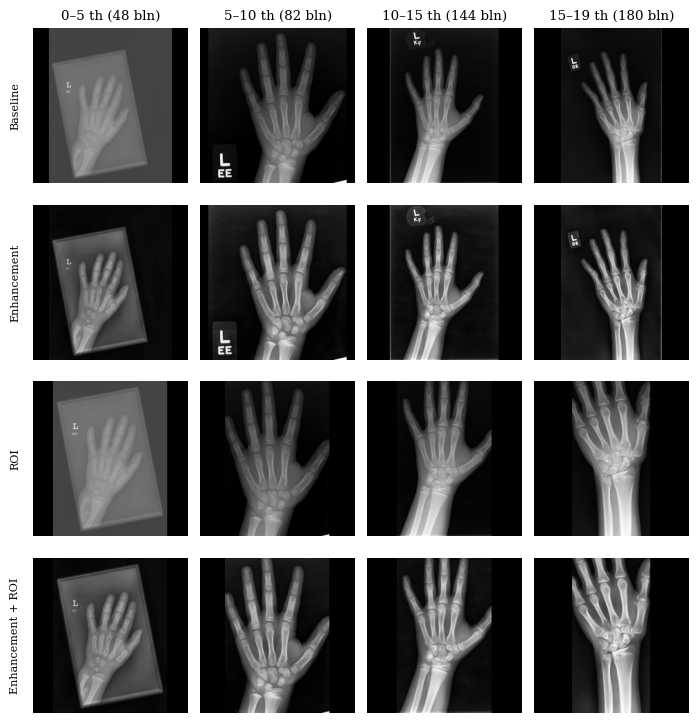

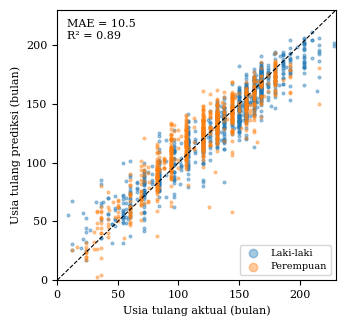

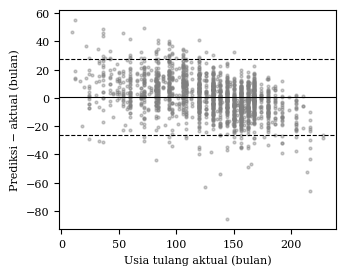

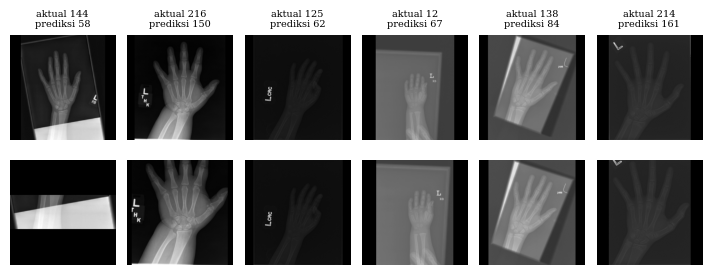

,id,aktual,prediksi,laki_laki,dibalik,roi_gagal
0,1966,144.0,58.2,0,0,0
1,13179,216.0,150.4,0,0,0
2,2662,125.0,62.3,0,0,1
3,1673,12.0,67.0,1,0,0
4,11880,138.0,83.9,1,0,0
5,2123,214.0,161.3,1,0,0


In [10]:
# =========================================================
# SEL 10 — Gambar: contoh preprocessing, scatter, residual, kasus gagal
# =========================================================
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 8, "font.family": "serif"})

LANG = "id"   # >>> UBAH ke "en" untuk label bahasa Inggris (versi final paper)
T = {"id": {"true": "Usia tulang aktual (bulan)", "pred": "Usia tulang prediksi (bulan)",
            "res": "Prediksi − aktual (bulan)", "m": "Laki-laki", "f": "Perempuan",
            "var": {"raw": "Baseline", "enh": "Enhancement", "roi": "ROI", "enh_roi": "Enhancement + ROI"},
            "act": "aktual", "prd": "prediksi"},
     "en": {"true": "Actual bone age (months)", "pred": "Predicted bone age (months)",
            "res": "Prediction − actual (months)", "m": "Male", "f": "Female",
            "var": {"raw": "Baseline", "enh": "Enhancement", "roi": "ROI", "enh_roi": "Enhancement + ROI"},
            "act": "actual", "prd": "pred."}}[LANG]

CHUNK = 1000
_chunks = sorted(glob.glob(f"{DRIVE_CACHE}/chunk_*.npz"))
def load_images(idx_list, variant):
    """Ambil citra tertentu dari cache tanpa memuat seluruh dataset."""
    imgs, inv, fb = [], [], []
    for i in idx_list:
        d = np.load(_chunks[i // CHUNK])
        imgs.append(d[variant][i % CHUNK]); inv.append(int(d["inv"][i % CHUNK])); fb.append(int(d["fb"][i % CHUNK]))
    return imgs, inv, fb

def save(fig, name):
    fig.savefig(f"{DRIVE_OUT}/{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(f"{DRIVE_OUT}/{name}.pdf", bbox_inches="tight")
    plt.show()

te_idx = np.where(te)[0]

# --- Gambar 2: satu contoh citra test per kelompok usia, 4 varian preprocessing ---
rng_fig = np.random.default_rng(SEED)
sample = [rng_fig.choice(te_idx[np.asarray(grp == g)]) for g in names]
fig, ax = plt.subplots(4, 4, figsize=(7.0, 7.4))
for r, v in enumerate(VARIANTS):
    imgs, _, _ = load_images(sample, v)
    for c, im in enumerate(imgs):
        ax[r, c].imshow(im, cmap="gray"); ax[r, c].axis("off")
        if r == 0: ax[r, c].set_title(f"{names[c]} ({y[sample[c]]:.0f} bln)" if LANG == "id" else f"{y[sample[c]]:.0f} months")
    ax[r, 0].text(-20, 112, T["var"][v], rotation=90, ha="right", va="center")
fig.tight_layout(); save(fig, "gambar2_contoh_preprocessing")

# --- Gambar 3a: scatter prediksi vs aktual (model final) ---
mt = metrics(yt, pt_f)
fig, ax = plt.subplots(figsize=(3.5, 3.3))
ax.scatter(yt[sex_te == 1], pt_f[sex_te == 1], s=4, alpha=0.4, label=T["m"])
ax.scatter(yt[sex_te == 0], pt_f[sex_te == 0], s=4, alpha=0.4, label=T["f"])
ax.plot([0, 230], [0, 230], "k--", lw=0.8)
ax.set_xlim(0, 230); ax.set_ylim(0, 230); ax.set_xlabel(T["true"]); ax.set_ylabel(T["pred"])
ax.text(8, 222, f"MAE = {mt['MAE']:.1f}\nR² = {mt['R2']:.2f}", va="top")
ax.legend(loc="lower right", markerscale=3, fontsize=7)
fig.tight_layout(); save(fig, "gambar3a_scatter")

# --- Gambar 3b: residual vs usia aktual (garis rata-rata dan ±1,96 SD) ---
res = pt_f - yt; mres, sres = res.mean(), res.std()
fig, ax = plt.subplots(figsize=(3.5, 2.8))
ax.scatter(yt, res, s=4, alpha=0.4, c="tab:gray")
for h, ls in [(mres, "-"), (mres + 1.96 * sres, "--"), (mres - 1.96 * sres, "--")]:
    ax.axhline(h, color="k", ls=ls, lw=0.8)
ax.set_xlabel(T["true"]); ax.set_ylabel(T["res"])
fig.tight_layout(); save(fig, "gambar3b_residual")

# --- Kasus gagal: 6 citra test dengan error absolut terbesar ---
worst = te_idx[np.argsort(-np.abs(res))[:6]]
raw_imgs, inv_w, fb_w = load_images(worst, "raw")
roi_imgs, _, _ = load_images(worst, "roi")
fig, ax = plt.subplots(2, 6, figsize=(7.16, 3.0))
for c, i in enumerate(worst):
    k = np.where(te_idx == i)[0][0]
    ax[0, c].imshow(raw_imgs[c], cmap="gray"); ax[1, c].imshow(roi_imgs[c], cmap="gray")
    ax[0, c].set_title(f"{T['act']} {yt[k]:.0f}\n{T['prd']} {pt_f[k]:.0f}", fontsize=7)
    ax[0, c].axis("off"); ax[1, c].axis("off")
fig.tight_layout(); save(fig, "gambar_kasus_gagal")

gagal = pd.DataFrame({"id": df["id"].values[worst], "aktual": y[worst],
                      "prediksi": [pt_f[np.where(te_idx == i)[0][0]] for i in worst],
                      "laki_laki": df["male"].values[worst], "dibalik": inv_w, "roi_gagal": fb_w})
gagal.to_csv(f"{DRIVE_OUT}/kasus_gagal.csv", index=False)
display(gagal.round(1))

In [11]:
# =========================================================
# SEL 11 — Catat lingkungan komputasi
# =========================================================
!nvidia-smi --query-gpu=name,memory.total --format=csv
import sys, platform, sklearn, xgboost, torchvision, scipy, psutil
print("Python      :", sys.version.split()[0])
print("PyTorch     :", torch.__version__, "| torchvision:", torchvision.__version__)
print("scikit-learn:", sklearn.__version__, "| XGBoost:", xgboost.__version__, "| SciPy:", scipy.__version__)
print("NumPy       :", np.__version__, "| pandas:", pd.__version__)
print("CPU cores   :", os.cpu_count(), "| RAM (GB):", round(psutil.virtual_memory().total / 1e9, 1))
print("OS          :", platform.platform())

/bin/bash: line 1: nvidia-smi: command not found
Python      : 3.13.16
PyTorch     : 2.11.0+cpu | torchvision: 0.26.0+cpu
scikit-learn: 1.6.1 | XGBoost: 3.4.1 | SciPy: 1.16.3
NumPy       : 2.1.3 | pandas: 2.2.3
CPU cores   : 2 | RAM (GB): 13.6
OS          : Linux-6.6.122+-x86_64-with-glibc2.39


In [12]:
# =========================================================
# SEL 12 — Ringkasan angka penting (salin seluruh output sel ini ke chat)
# =========================================================
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
print(f"Baseline MAE val {BASE_VAL:.2f} | test {BASE_TEST:.2f}")
print("Varian terbaik:", VAR, "| Model final:", FINAL_NAME, FINAL["params"])
print("\n[Tabel 1] Ablation\n", tab1[COLS].round(2).to_string(index=False))
print("\n[Tabel 2] Backbone x regressor\n", tab2[COLS].round(2).to_string(index=False))
print("\nParameter terbaik + info:\n", "\n".join(f"  {k}: {v['params']} {v['info']}" for k, v in best_per.items()))
print("\n[Tabel 3] Ensemble\n", tab3[COLS].round(2).to_string(index=False))
print("\n[Fitur gender]\n", tab_sex[["regressor", "use_sex", "val_MAE", "test_MAE", "test_R2"]].round(2).to_string(index=False))
print("\n[Per usia]\n", tab_age.round(2).to_string(index=False))
print("\n[Per jenis kelamin]\n", tab_sexgrp.round(2).to_string(index=False))
print("\n[Bootstrap CI MAE]\n", tab_ci.round(2).to_string(index=False))
print("\n[Bootstrap selisih]\n", tab_diff.round(2).to_string(index=False))
print("\n[Kasus gagal]\n", gagal.round(1).to_string(index=False))

Baseline MAE val 33.78 | test 33.60
Varian terbaik: roi | Model final: ensemble + bobot (val) {'resnet50': np.float64(0.2), 'densenet121': np.float64(0.5), 'efficientnet_b0': np.float64(0.3)}

[Tabel 1] Ablation
 backbone variant regressor                params  val_MAE  test_MAE  test_RMSE  test_R2  test_Pearson
resnet50     raw     ridge       {'alpha': 1000}    14.28     14.11      18.13     0.80          0.90
resnet50     raw       svr {'C': 10, 'eps': 0.1}    15.40     15.02      19.71     0.77          0.88
resnet50     enh     ridge       {'alpha': 1000}    14.13     14.47      18.41     0.80          0.89
resnet50     enh       svr {'C': 10, 'eps': 0.1}    15.09     14.91      19.32     0.78          0.88
resnet50     roi     ridge        {'alpha': 100}    13.59     13.78      17.99     0.81          0.90
resnet50     roi       svr {'C': 10, 'eps': 0.1}    15.01     14.61      19.36     0.78          0.88
resnet50 enh_roi     ridge       {'alpha': 1000}    13.75     13.85      